# Rental Price Estimation in Saudi Arabia: Week 2
**Razan Mohammed Alqarni**

**Research question:** Are rental price models equally accurate across Saudi cities, and how do data quality issues affect the reported accuracy?

Week 2: model comparison with cross-validation, and the district as a new feature.

## 1. Load and clean the data (Week 1 rules)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("../Saudi_Arabia_Real_Estate_AQAR.csv")
df["city"] = df["city"].str.strip()
df["district"] = df["district"].str.strip()
df["city"] = df["city"].map({"الرياض": "Riyadh", "جدة": "Jeddah", "الدمام": "Dammam", "الخبر": "Khobar"})
print("Raw rows:", len(df))

df = df.drop_duplicates()
df = df[(df["price"] >= 15000) & (df["price"] <= 400000)]
df = df[(df["size"] >= 50) & (df["size"] <= 2000)].reset_index(drop=True)
print("Clean, deduplicated rows:", len(df))

Raw rows: 3718
Clean, deduplicated rows: 1472


In [2]:
df.groupby("city").agg(rows=("price", "size"), districts=("district", "nunique"), median_price=("price", "median"))

,rows,districts,median_price
city,,,
Dammam,119,26,60000.0
Jeddah,392,49,100000.0
Khobar,82,25,65000.0
Riyadh,879,107,80000.0


## 2. Two feature sets
- **Feature set A** = the Week 1 features: numeric columns plus one-hot city and front.
- **Feature set B** = A plus the district.

The models are trained on log(price), because prices are skewed. Predictions are converted back with exp() before computing the errors, so MAE is in SAR.

In [3]:
X_a = pd.get_dummies(df.drop(columns=["price", "details", "district"]), columns=["city", "front"], dtype=int)
y = df["price"]
y_log = np.log(y)
print(X_a.shape)
X_a.columns.tolist()

(1472, 33)


['size',
 'property_age',
 'bedrooms',
 'bathrooms',
 'livingrooms',
 'kitchen',
 'garage',
 'driver_room',
 'maid_room',
 'furnished',
 'ac',
 'roof',
 'pool',
 'frontyard',
 'basement',
 'duplex',
 'stairs',
 'elevator',
 'fireplace',
 'city_Dammam',
 'city_Jeddah',
 'city_Khobar',
 'city_Riyadh',
 'front_3 شوارع',
 'front_4 شوارع',
 'front_جنوب',
 'front_جنوب شرقي',
 'front_جنوب غربي',
 'front_شرق',
 'front_شمال',
 'front_شمال شرقي',
 'front_شمال غربي',
 'front_غرب']

### Encoding the district
There are about 200 districts, many with only a few listings, so one-hot encoding would create a very wide and sparse matrix. Instead the district is replaced by the **mean log price of its district**, smoothed toward the city mean:

`encoded = (sum of log prices in district + k * city mean) / (count in district + k)`, with k = 10.

A district with many listings keeps its own mean, a district with 1 or 2 listings is pulled toward its city mean. A district that appears only in the test part gets the city mean.

**Why the encoding must be done inside each fold:** the encoded value is computed from the target (price). If it were computed once on the whole dataset, every test row would carry information about its own price into the feature, and the test score would be too optimistic (target leakage). So in every fold the district means are computed from the training part only, and then applied to the test part.

In [4]:
def encode_district(train, test, log_price_train, smoothing=10):
    train = train[["city", "district"]].assign(log_price=log_price_train.values)
    city_mean = train.groupby("city")["log_price"].mean()
    stats = train.groupby(["city", "district"])["log_price"].agg(["sum", "count"]).reset_index()
    stats["city_mean"] = stats["city"].map(city_mean)
    stats["district_enc"] = (stats["sum"] + smoothing * stats["city_mean"]) / (stats["count"] + smoothing)
    stats = stats[["city", "district", "district_enc"]]
    encoded = []
    for part in (train, test):
        enc = part[["city", "district"]].merge(stats, on=["city", "district"], how="left")["district_enc"]
        enc = enc.fillna(part["city"].map(city_mean).reset_index(drop=True))
        encoded.append(enc.values)
    return encoded

## 3. Model comparison with repeated cross-validation
5-fold cross-validation repeated 3 times (15 test folds in total). Each row is predicted 3 times, once per repeat, and these predictions are averaged for the per-city analysis in section 4.

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

def cross_validate(model, use_district):
    maes, r2s = [], []
    pooled = np.zeros(len(df))
    for train_idx, test_idx in cv.split(X_a):
        X_train, X_test = X_a.iloc[train_idx].copy(), X_a.iloc[test_idx].copy()
        if use_district:
            enc_train, enc_test = encode_district(df.iloc[train_idx], df.iloc[test_idx], y_log.iloc[train_idx])
            X_train["district_enc"] = enc_train
            X_test["district_enc"] = enc_test
        model.fit(X_train, y_log.iloc[train_idx])
        pred = np.exp(model.predict(X_test))
        maes.append(mean_absolute_error(y.iloc[test_idx], pred))
        r2s.append(r2_score(y.iloc[test_idx], pred))
        pooled[test_idx] += pred / cv.n_repeats
    return np.mean(maes), np.std(maes), np.mean(r2s), np.std(r2s), pooled

In [6]:
rows, pooled_preds = [], {}
for feature_set, use_district in [("A: Week 1 features", False), ("B: A + district", True)]:
    for name, model in models.items():
        mae, mae_sd, r2, r2_sd, pooled = cross_validate(model, use_district)
        rows.append([feature_set, name, mae, mae_sd, r2, r2_sd])
        pooled_preds[(feature_set, name)] = pooled

results = pd.DataFrame(rows, columns=["Feature set", "Model", "MAE", "MAE sd", "R2", "R2 sd"])
table = results[["Feature set", "Model"]].copy()
table["MAE (SAR)"] = results["MAE"].round(0).astype(int).astype(str) + " ± " + results["MAE sd"].round(0).astype(int).astype(str)
table["R2"] = results["R2"].round(3).astype(str) + " ± " + results["R2 sd"].round(3).astype(str)
table

,Feature set,Model,MAE (SAR),R2
0,A: Week 1 features,Linear Regression,28085 ± 1778,0.395 ± 0.097
1,A: Week 1 features,Ridge,28055 ± 1796,0.396 ± 0.097
2,A: Week 1 features,Random Forest,27237 ± 1795,0.438 ± 0.06
3,A: Week 1 features,Gradient Boosting,27836 ± 1582,0.429 ± 0.063
4,B: A + district,Linear Regression,22683 ± 1592,0.567 ± 0.066
5,B: A + district,Ridge,22636 ± 1604,0.567 ± 0.065
6,B: A + district,Random Forest,21999 ± 1792,0.56 ± 0.05
7,B: A + district,Gradient Boosting,21975 ± 1561,0.589 ± 0.049


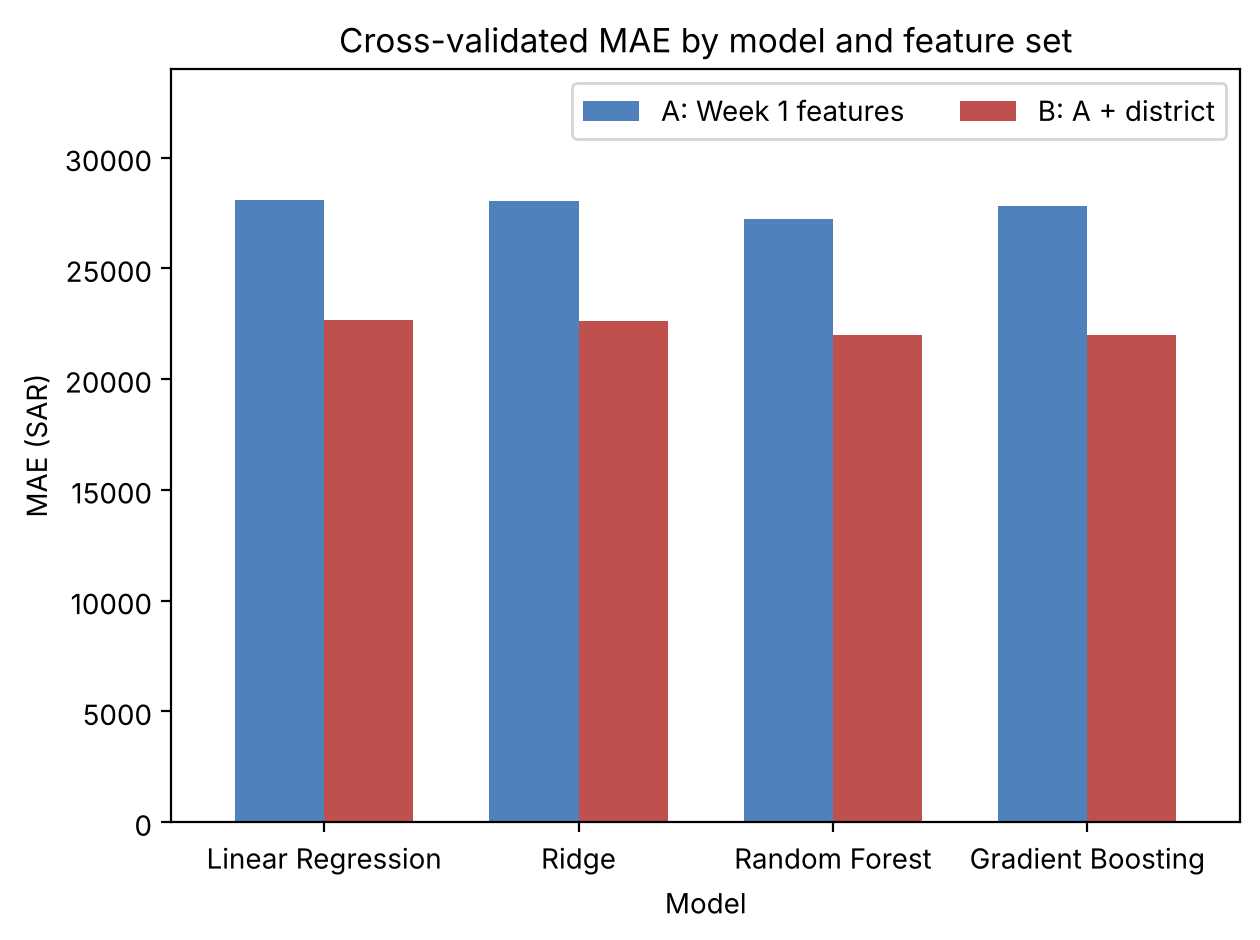

In [7]:
pivot = results.pivot(index="Model", columns="Feature set", values="MAE").loc[list(models)]
pivot.plot(kind="bar", color=["#4f81bd", "#c0504d"], width=0.7)
plt.ylabel("MAE (SAR)")
plt.ylim(0, 34000)
plt.title("Cross-validated MAE by model and feature set")
plt.xticks(rotation=0)
plt.legend(title=None, loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

## 4. Error by city for the best model
The per-city errors use the pooled cross-validated predictions, so every city's error is based on all of its rows, not on a small random test set.

In [8]:
best = results.sort_values("MAE").iloc[0]
print("Best model:", best["Model"], "with", best["Feature set"])

out = pd.DataFrame({"city": df["city"], "actual": y, "pred": pooled_preds[(best["Feature set"], best["Model"])]})
out["abs_error"] = (out["actual"] - out["pred"]).abs()
out["pct_error"] = out["abs_error"] / out["actual"] * 100
by_city = out.groupby("city").agg(rows=("actual", "size"),
                                  median_price=("actual", "median"),
                                  MAE=("abs_error", "mean"),
                                  MAPE_pct=("pct_error", "mean")).round(1)
by_city.sort_values("MAPE_pct", ascending=False)

Best model: Gradient Boosting with B: A + district


,rows,median_price,MAE,MAPE_pct
city,,,,
Jeddah,392,100000.0,30063.2,28.1
Khobar,82,65000.0,20296.2,24.1
Riyadh,879,80000.0,19142.1,20.7
Dammam,119,60000.0,10212.7,15.0


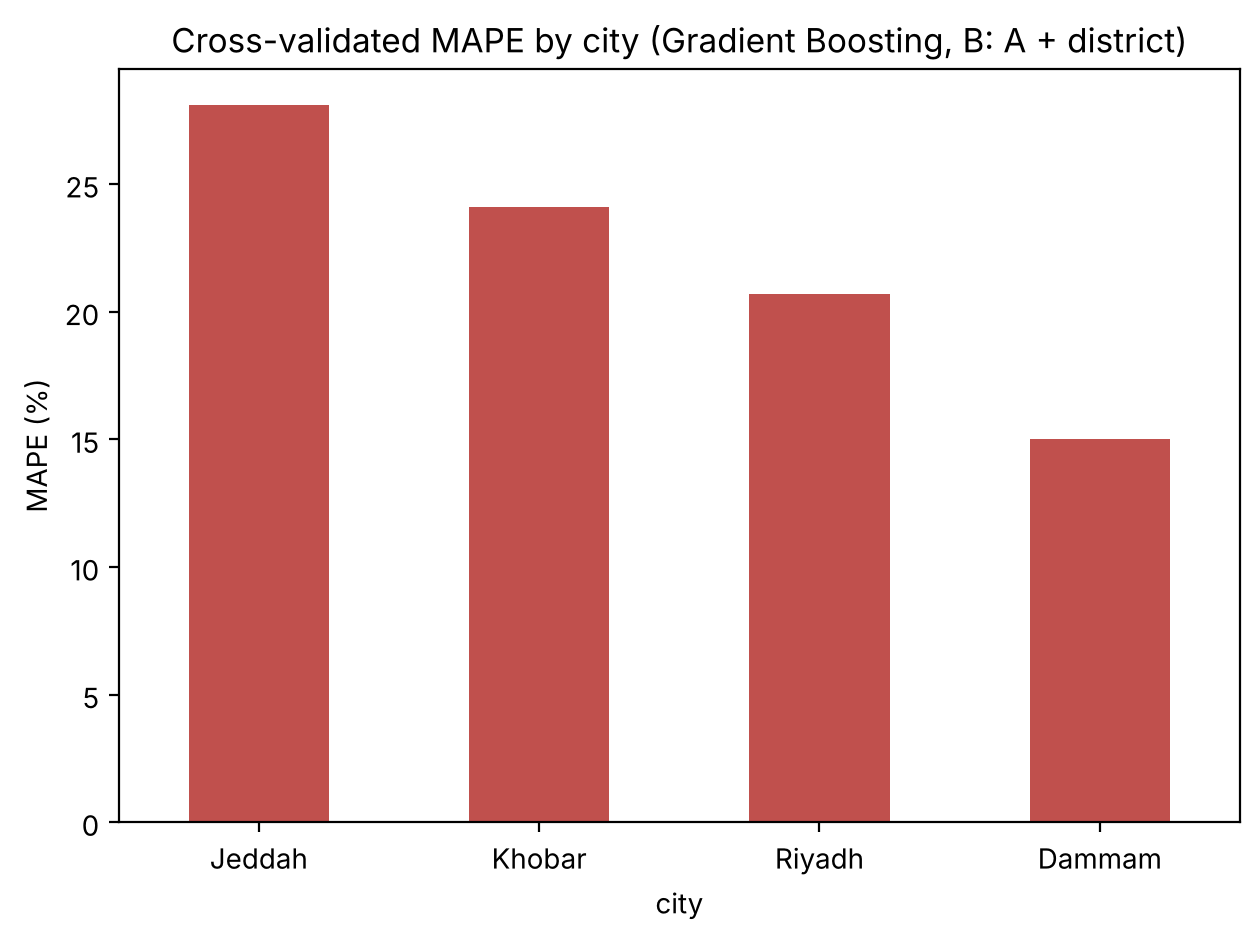

In [9]:
by_city["MAPE_pct"].sort_values(ascending=False).plot(kind="bar", color="#c0504d")
plt.ylabel("MAPE (%)")
plt.title("Cross-validated MAPE by city (" + best["Model"] + ", " + best["Feature set"] + ")")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Week 2 findings
1. **Best model:** Gradient Boosting with feature set B (A + district) has the lowest MAE (about 22,000 SAR) and the highest R² (about 0.59). Random Forest is very close on MAE; the two linear models are about 700 SAR behind. Within one feature set the models differ by much less than the fold-to-fold standard deviation, so the choice of model matters less than the choice of features.
2. **The district adds a lot:** adding the smoothed district encoding lowers the MAE of every model by about 5,000 to 5,500 SAR (roughly 19%) and raises R² from about 0.40 to 0.44 up to 0.57 to 0.59. Location inside the city is the strongest single piece of information that was missing in Week 1.
3. **Hardest city:** Jeddah has the largest errors (MAE about 30,000 SAR, MAPE about 28%), followed by Khobar (MAPE about 24%). Riyadh sits around 21% and Dammam is the easiest at about 15%, partly because its prices are lower and less spread out.
4. **Limitation:** after removing duplicates Khobar has only 82 unique listings and Dammam only 119, spread over about 25 districts each. Their per-city errors are therefore based on few listings and few examples per district, so the Dammam and Khobar numbers are much less stable than those for Riyadh (879 rows) and Jeddah (392 rows), and the district encoding falls back to the city mean for many of their districts.

**Next (Week 3):** error analysis by city and property type, and SHAP interpretation of the Gradient Boosting model.